# 01 · Data exploration — EMBER 2018 (host / PE domain)

**EMBER 2018** contains static features of 1M Windows PE files (800k train, 200k test) extracted with LIEF.
Every file is described by a 2381-dimensional vector grouped in feature families (byte histogram, byte-entropy
histogram, strings, general info, header, sections, imports, exports, data directories).

In this project each family becomes **one node** of the PE graph (see notebook 02), and the `appeared` month is used to build
a **chronological split** (train = January 2018, test = February–December 2018) to measure concept drift.

What this notebook checks:
1. class balance (and the unlabeled portion that we discard);
2. how samples are distributed over time (needed to interpret drift);
3. which raw features separate benign from malware, family by family.

The vectorised `.dat` files are read with `np.memmap`, so the 7 GB training matrix is never fully loaded in RAM and the
`ember` package is not required.

In [1]:
import sys
import json
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # torch.jit / pandas deprecations
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm without ipywidgets
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.utils.config import CONFIG

EXP = project_root / CONFIG["experiments_path"]
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.dpi": 110})
GNN_NAME = "GNN (MFGraph)"


def latest_run(base: Path, filename: str):
    """Most recent timestamped run folder under `base` that contains `filename`."""
    runs = sorted(p.parent for p in base.glob(f"*/{filename}")) if base.exists() else []
    return runs[-1] if runs else None


def missing(path, task):
    print(f"[Missing] {path}\nRun first:  python orchestrator.py -t {task}")

In [2]:
EMBER_DIR = project_root / CONFIG["ember_path"]
N_FEATURES = 2381  # EMBER feature version 2

y_train = np.memmap(EMBER_DIR / "y_train.dat", dtype=np.float32, mode="r")
X_train = np.memmap(EMBER_DIR / "X_train.dat", dtype=np.float32, mode="r", shape=(len(y_train), N_FEATURES))
y_test = np.memmap(EMBER_DIR / "y_test.dat", dtype=np.float32, mode="r")

print(f"Train: {X_train.shape[0]:,} samples x {X_train.shape[1]} features")
print(f"Test:  {len(y_test):,} samples")

Train: 800,000 samples x 2381 features
Test:  200,000 samples


## 1. Label distribution

EMBER labels are `0 = benign`, `1 = malware`, `-1 = unlabeled`. Unlabeled samples are kept in the original release for
semi-supervised research; this project drops them.

,train,test,train_pct
Benign,300000,100000,37.5
Malware,300000,100000,37.5
Unlabeled,200000,0,25.0


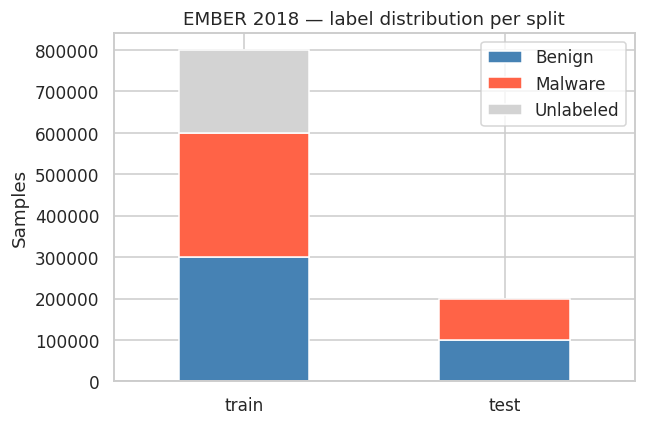

In [3]:
def counts(y):
    return pd.Series({"Benign": (y == 0).sum(), "Malware": (y == 1).sum(), "Unlabeled": (y == -1).sum()})

dist = pd.DataFrame({"train": counts(y_train), "test": counts(y_test)})
display(dist.assign(train_pct=lambda d: (100 * d.train / d.train.sum()).round(1)))

ax = dist.T.plot(kind="bar", stacked=True, color=["steelblue", "tomato", "lightgray"], figsize=(6, 4), rot=0)
ax.set_ylabel("Samples"); ax.set_title("EMBER 2018 — label distribution per split")
plt.tight_layout(); plt.show()

The labelled data is **perfectly balanced** (300k/300k in train, 100k/100k in test), so accuracy is not misleading here
and no re-weighting is needed for the PE models. A quarter of the train set is unlabeled and is discarded.

## 2. Temporal distribution

The concept-drift experiment depends on *when* each file was first seen. The metadata file has the `appeared` month.

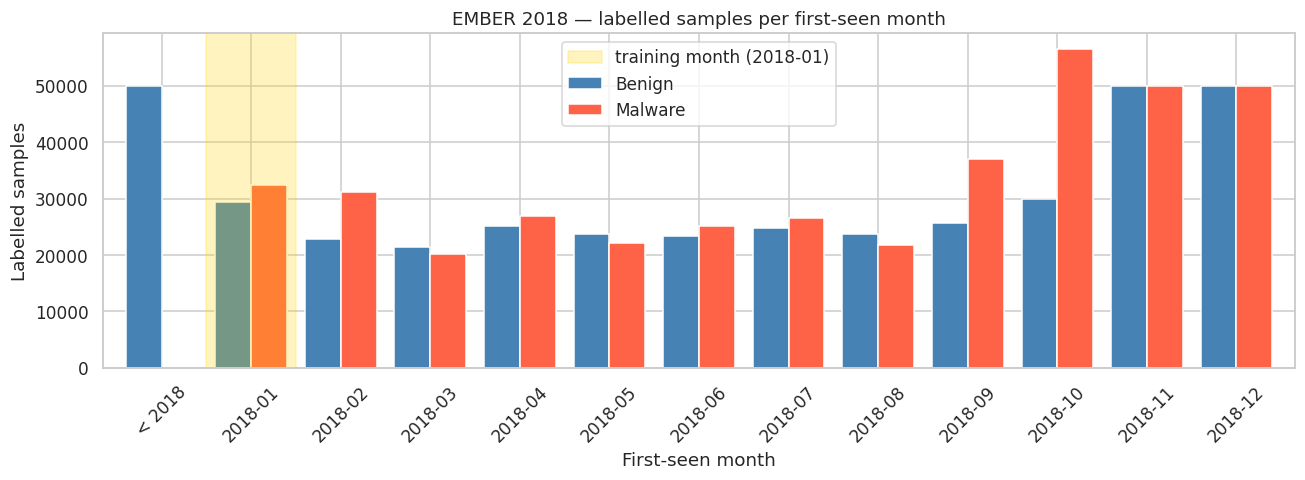

label,Benign,Malware,split
period,,,
< 2018,50000,0,not used
2018-01,29423,32491,train (GNN)
2018-02,22915,31222,test (drift)
2018-03,21373,20152,test (drift)
2018-04,25190,26892,test (drift)
2018-05,23719,22193,test (drift)
2018-06,23285,25116,test (drift)
2018-07,24799,26622,test (drift)
2018-08,23634,21791,test (drift)


In [4]:
meta = pd.read_csv(EMBER_DIR / "metadata.csv", usecols=["appeared", "label", "subset"])
meta = meta[meta.label != -1]
# Files first seen before 2018 are a long sparse tail (2006-2017): group them in one bucket
meta["period"] = np.where(meta.appeared < "2018-01", "< 2018", meta.appeared)
by_month = (meta.groupby(["period", "label"]).size().unstack(fill_value=0)
            .rename(columns={0: "Benign", 1: "Malware"}))
by_month = by_month.loc[["< 2018"] + sorted(i for i in by_month.index if i != "< 2018")]
by_month["split"] = np.where(by_month.index == "2018-01", "train (GNN)",
                             np.where(by_month.index == "< 2018", "not used", "test (drift)"))

fig, ax = plt.subplots(figsize=(12, 4.5))
by_month[["Benign", "Malware"]].plot(kind="bar", ax=ax, color=["steelblue", "tomato"], width=0.8, rot=45)
jan = by_month.index.get_loc("2018-01")
ax.axvspan(jan - 0.5, jan + 0.5, color="gold", alpha=0.25, label="training month (2018-01)")
ax.set_xlabel("First-seen month"); ax.set_ylabel("Labelled samples")
ax.set_title("EMBER 2018 — labelled samples per first-seen month")
ax.legend()
plt.tight_layout(); plt.show()
display(by_month)

Files first seen before 2018 are almost only benign and are not used. Within 2018 the class ratio changes from month
to month, and November–December are larger, balanced blocks (they form the original EMBER test set). Training the GNN on
**January 2018 only** and testing on each later month is therefore a realistic "deploy and wait" scenario:
any drop in later months is due to new malware families and new benign software, not to label leakage.

## 3. Feature statistics per family

Raw values span very different ranges (file size in bytes vs. normalised histograms), which is why the graph builder
L2-normalises every node vector. A random sample of 20k labelled rows is enough for statistics.

In [5]:
FAMILIES = {  # EMBER v2 column ranges
    "byte_histogram": (0, 256), "byte_entropy": (256, 512), "string": (512, 616),
    "general": (616, 626), "header": (626, 688), "section": (688, 943),
    "imported": (943, 2223), "exported": (2223, 2351), "data_directories": (2351, 2381),
}

rng = np.random.default_rng(CONFIG["random_seed"])
labelled_idx = np.where(y_train != -1)[0]
idx = np.sort(rng.choice(labelled_idx, 20_000, replace=False))
X_s, y_s = np.asarray(X_train[idx]), np.asarray(y_train[idx]).astype(int)

rows = []
for fam, (a, b) in FAMILIES.items():
    block = X_s[:, a:b]
    rows.append({"family": fam, "dims": b - a, "min": block.min(), "max": block.max(),
                 "mean": block.mean(), "% zeros": 100 * (block == 0).mean()})
display(pd.DataFrame(rows).set_index("family").round(3))

,dims,min,max,mean,% zeros
family,,,,,
byte_histogram,256,0.0,9.990000e-01,4.000000e-03,1.667
byte_entropy,256,0.0,9.980000e-01,4.000000e-03,34.079
string,104,0.0,5.034687e+07,1.142882e+03,6.775
general,10,0.0,6.579896e+08,3.254305e+05,46.941
header,62,-2.0,4.294967e+09,2.178368e+07,76.122
section,255,-636485632.0,3.163986e+08,-1.781866e+03,90.908
imported,1280,-83163.0,7.090000e+02,-7.000000e-03,92.889
exported,128,-693.0,2.900000e+01,0.000000e+00,97.327
data_directories,30,0.0,4.294967e+09,5.903486e+05,67.447


The import/export families are extremely sparse (feature hashing), while histograms are dense and bounded.
This heterogeneity is one motivation for a graph: each family keeps its own node instead of being mixed into one flat vector.

## 4. Which features separate the classes?

Instead of plotting arbitrary columns, rank all features by the **standardised mean difference** (Cohen's d) between
malware and benign, then look at the distributions of the most discriminative named features.

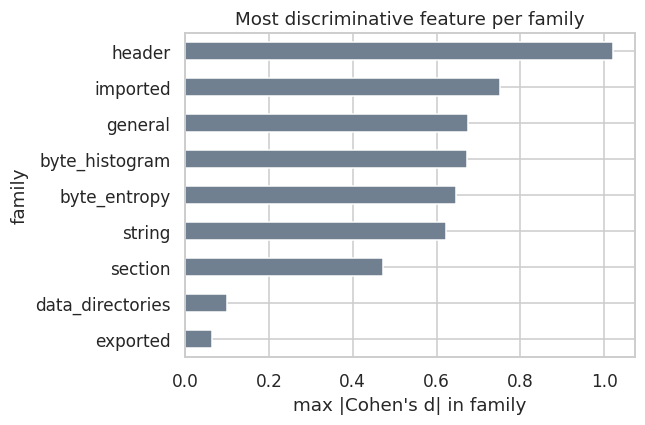

In [6]:
mu_b, mu_m = X_s[y_s == 0].mean(0), X_s[y_s == 1].mean(0)
sd = np.sqrt((X_s[y_s == 0].var(0) + X_s[y_s == 1].var(0)) / 2) + 1e-9
d = (mu_m - mu_b) / sd

fam_of = np.empty(N_FEATURES, dtype=object)
for fam, (a, b) in FAMILIES.items():
    fam_of[a:b] = fam

eff = pd.DataFrame({"family": fam_of, "abs_d": np.abs(d)})
ax = eff.groupby("family")["abs_d"].max().sort_values().plot(kind="barh", color="slategray", figsize=(6, 4))
ax.set_xlabel("max |Cohen's d| in family"); ax.set_title("Most discriminative feature per family")
plt.tight_layout(); plt.show()

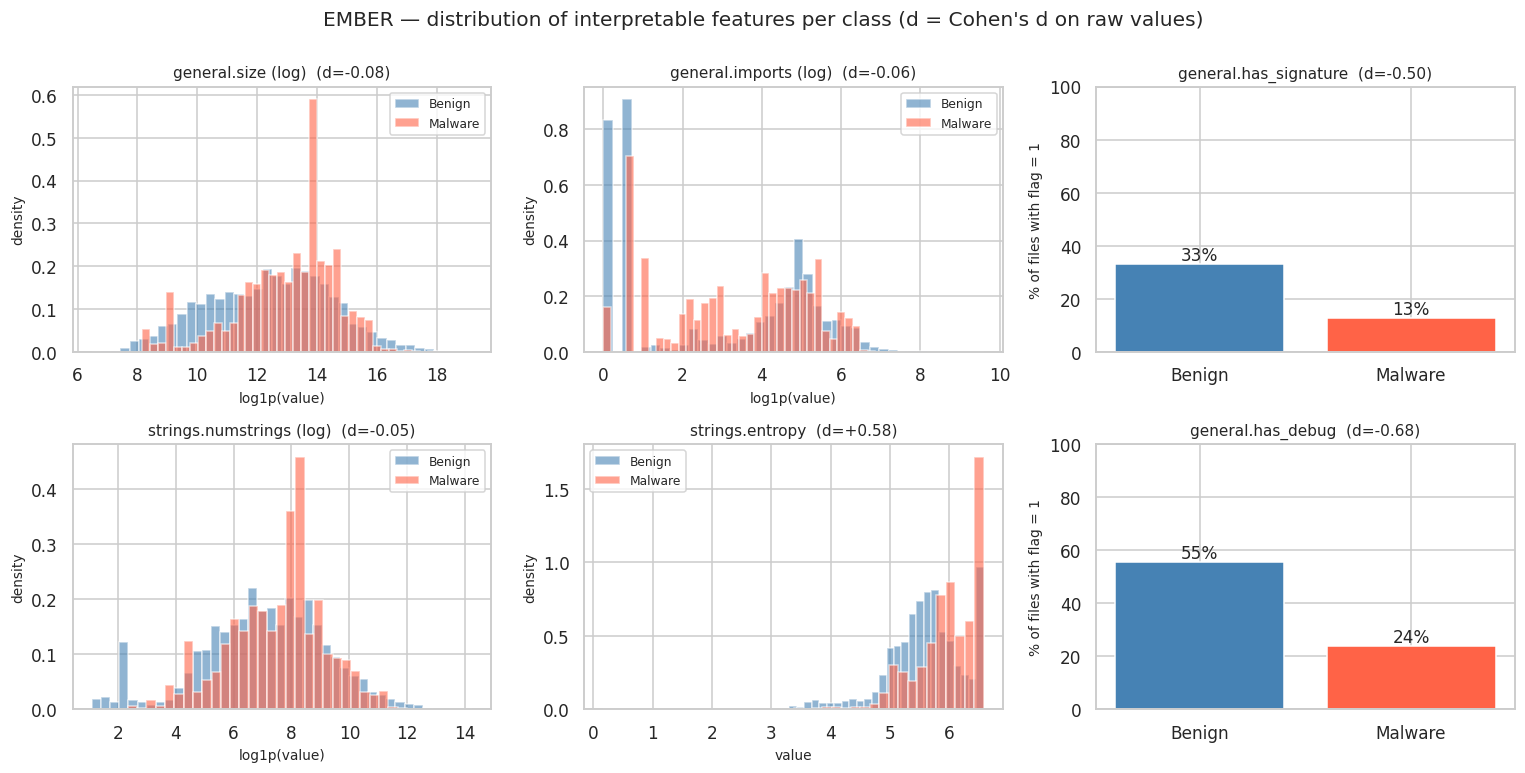

In [7]:
NAMED = {  # interpretable columns of EMBER v2
    "general.size (log)": 616, "general.imports (log)": 620, "general.has_signature": 623,
    "strings.numstrings (log)": 512, "strings.entropy": 611, "general.has_debug": 618,
}
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (name, col) in zip(axes.ravel(), NAMED.items()):
    v = X_s[:, col]
    if name.startswith("general.has_"):
        # binary flag: share of files with the flag, per class
        share = pd.Series({"Benign": v[y_s == 0].mean(), "Malware": v[y_s == 1].mean()}) * 100
        ax.bar(share.index, share.values, color=["steelblue", "tomato"])
        for i, val in enumerate(share.values):
            ax.text(i, val, f"{val:.0f}%", ha="center", va="bottom")
        ax.set_title(f"{name}  (d={d[col]:+.2f})", fontsize=10)
        ax.set_ylabel("% of files with flag = 1", fontsize=9); ax.set_ylim(0, 100)
        continue
    if "log" in name:
        v = np.log1p(np.clip(v, 0, None))
    for lbl, c, txt in [(0, "steelblue", "Benign"), (1, "tomato", "Malware")]:
        ax.hist(v[y_s == lbl], bins=40, alpha=0.6, density=True, color=c, label=txt)
    ax.set_title(f"{name}  (d={d[col]:+.2f})", fontsize=10)
    ax.set_xlabel("log1p(value)" if "log" in name else "value", fontsize=9)
    ax.set_ylabel("density", fontsize=9)
    ax.legend(fontsize=8)
plt.suptitle("EMBER — distribution of interpretable features per class (d = Cohen's d on raw values)", y=1.0)
plt.tight_layout()
plt.savefig(EXP / "ember_feature_distributions.png", dpi=150)
plt.show()

**Takeaways**
* Single features overlap heavily between classes: no column alone is a good detector, which justifies models that combine families.
* The strongest single features are in the **header** and **imports** families (|d| ≈ 1.0 and 0.75); among the interpretable
  ones, debug info, signature presence and string entropy carry the most signal, while size and counts barely differ.
  Several of these are cheap for an attacker to change (stripping debug info, packing to raise entropy), which motivates
  the robustness experiments in notebook 05.
* The data is balanced, so F1 and AUC on the PE side are directly comparable across months.